# Forest Fires Prevention Summative Lab

## Introduction

As a junior data scientist at a forestry management company, your role is to support efforts to reduce the damage caused by wildfires by identifying patterns in past fire occurrences and predicting areas at high risk. Wildfires are highly unpredictable and influenced by environmental conditions, weather patterns, and geographic factors. The company relies on data-driven insights to allocate firefighting resources efficiently and implement preventive measures before fires escalate.

**Using the Forest Fires dataset, your primary objective is to:**
- Analyze the factors that contribute to fire size and severity.
- Develop models that predict high-risk areas.
- Provide actionable recommendations to aid in risk mitigation.

This requires analyzing environmental factors such as temperature, humidity, wind speed, and precipitation to determine which conditions most strongly influence wildfire behavior. Additionally, you must determine whether certain geographic factors, such as proximity to urban areas, vegetation density, or elevation, play a role in fire intensity and spread.

Your work will help forestry professionals and emergency response teams make informed decisions about where to deploy resources, when to issue alerts, and how to minimize destruction caused by wildfires.

## Challenges for This Lab

- **Data Understanding and Preprocessing:** Analyzing the dataset structure, handling missing values or inconsistencies, and applying necessary transformations to prepare the data for modeling.
- **Feature Selection and Engineering for Regression:** Identifying the most relevant predictors, handling multicollinearity, and applying transformations or interactions to improve model performance.
- **Model Selection and Performance Evaluation:** Comparing multiple regression models based on statistical metrics, residual diagnostics, and model assumptions to determine the best fit.
- **Applying Regularization for Improved Generalization:** Using Ridge and Lasso regression to address overfitting and multicollinearity while interpreting the trade-off between feature selection and regularization strength.
- **Transitioning from Regression to Classification:** Converting the target variable into a binary classification problem, training a logistic regression model, and evaluating its predictive performance.
- **Final Model Interpretation and Decision-Making:** Synthesizing findings from regression and classification models, comparing trade-offs, and recommending the best approach for predicting or classifying fire behavior.

In [24]:
# Import any useful libraries:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from scipy.stats import pearsonr
import statsmodels.api as sm
import statsmodels.formula.api as smf
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

### Step 1: Load the Dataset

- Install and import the `ucimlrepo` library.
- Load the Forest Fires dataset:
    - **Predictors:** Features from `forest_fires.data.features`.
    - **Target:** `forest_fires.data.targets`.

In [25]:
# Run `pip install` if necessary to access the UCI ML Repository:
# ! pip install ucimlrepo

In [26]:
# Load the Forest Fires dataset:
from ucimlrepo import fetch_ucirepo

forest_fires = fetch_ucirepo(id = 162)

# Define the predictors (X) and the response variable (y):
X = forest_fires.data.features
y = forest_fires.data.targets

# Display the dataset's structure:
print(X.info())
print(X.describe())
print(y.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    object 
 3   day     517 non-null    object 
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
dtypes: float64(7), int64(3), object(2)
memory usage: 48.6+ KB
None
                X           Y        FFMC         DMC          DC         ISI  \
count  517.000000  517.000000  517.000000  517.000000  517.000000  517.000000   
mean     4.669246    4.299807   90.644681  110.872340  547.940039    9.021663   
std      2.313778    1.229900    5.520111   64.046482  248.066192 

### Step 2: Exploratory Data Analysis (EDA)

- Examine the dataset's structure and summary statistics.
- Analyze correlations between predictors and the target variable.
- Plot scatterplots for key predictors vs. the target.
- Generate a residual plot to check for randomness in residuals.

We already examined the dataset's structure and summary statistics in the provided code in Step 1, so I will not be doing that again here.

In [27]:
# Analyze correlations between predictors and the target variable:
data = X.copy()
data["area"] = y["area"]

correlations = data.select_dtypes(include = "number").corr()["area"].\
               sort_values(ascending = False)

print(correlations)

area    1.000000
temp    0.097844
DMC     0.072994
X       0.063385
DC      0.049383
Y       0.044873
FFMC    0.040122
wind    0.012317
ISI     0.008258
rain   -0.007366
RH     -0.075519
Name: area, dtype: float64


None of these predictor variables have particularly strong correlations with the target variable, `area`. `Temp` (0.097844) and `DMC` (0.072994) have the strongest positive correlations. `RH` (-0.075519) has the strongest negative correlation, while `rain` (-0.007366) has a correlation very close to zero.

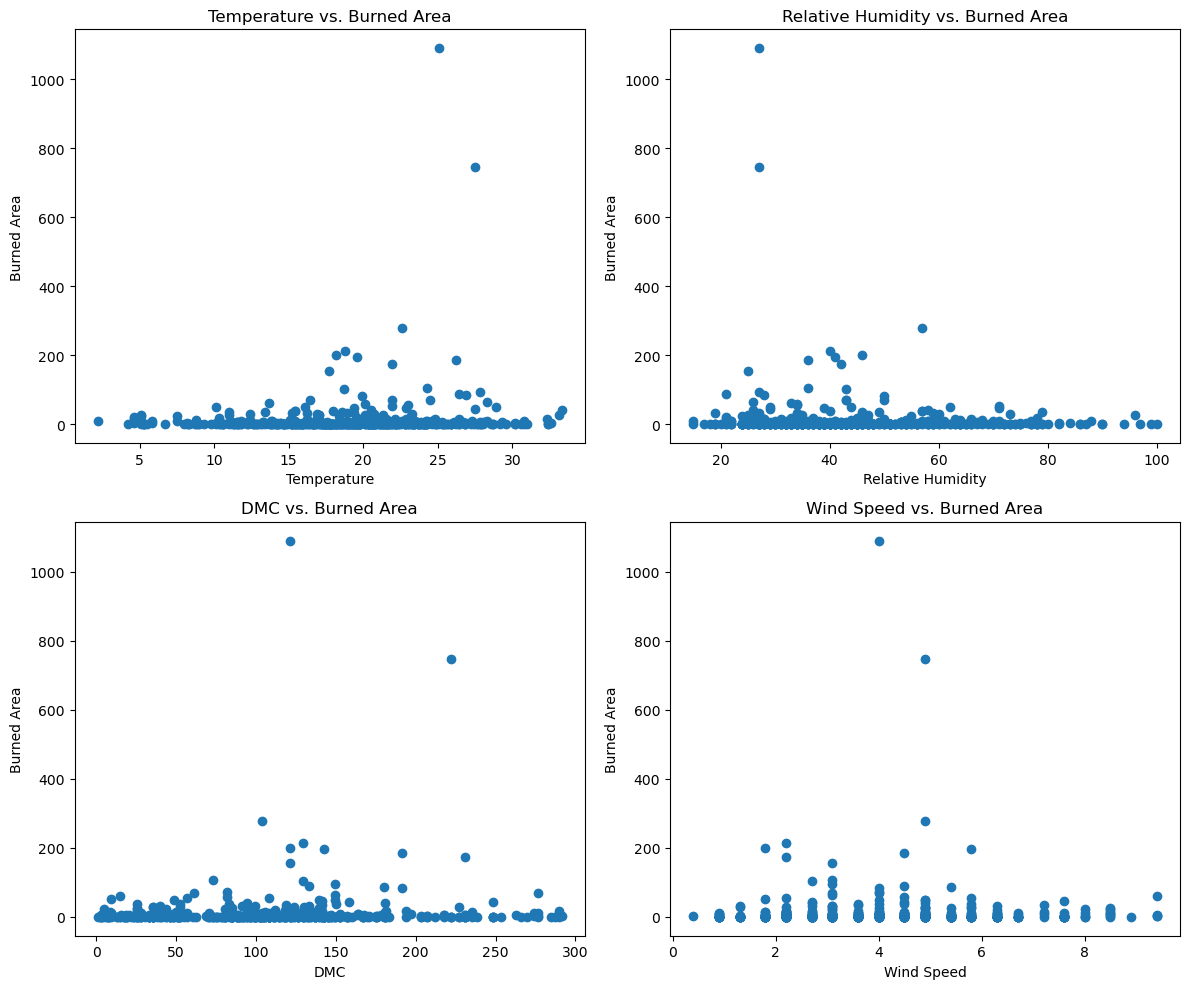

In [28]:
# Create scatterplots for key predictors vs. the target variable:

# Create a 2x2 plot with four subplots:
fig, axes = plt.subplots(2, 2, figsize = (12, 10))

# Plot `temp` vs. burned `area` (strongest positive correlation):
axes[0, 0].scatter(data["temp"], data["area"])
axes[0, 0].set_xlabel("Temperature")
axes[0, 0].set_ylabel("Burned Area")
axes[0, 0].set_title("Temperature vs. Burned Area")

# Plot `RH` (relative humidity) vs. burned `area` (strongest negative
# correlation):
axes[0, 1].scatter(data["RH"], data["area"])
axes[0, 1].set_xlabel("Relative Humidity")
axes[0, 1].set_ylabel("Burned Area")
axes[0, 1].set_title("Relative Humidity vs. Burned Area")

# Plot `DMC` vs. burned `area` (second-strongest positive correlation):
axes[1, 0].scatter(data["DMC"], data["area"])
axes[1, 0].set_xlabel("DMC")
axes[1, 0].set_ylabel("Burned Area")
axes[1, 0].set_title("DMC vs. Burned Area")

# Plot `wind` vs. burned `area` (generally useful for wildfire spread):
axes[1, 1].scatter(data["wind"], data["area"])
axes[1, 1].set_xlabel("Wind Speed")
axes[1, 1].set_ylabel("Burned Area")
axes[1, 1].set_title("Wind Speed vs. Burned Area")

plt.tight_layout()
# Display the graphs:
plt.show()

I have not made any regression model yet, so I cannot make a residual plot. I will make the regression models in Step 3 and then I can do a residual plot afterwards.

### Step 3: Fit the Regression Models

- Fit a baseline multiple linear regression model with key predictors.
- Include nonlinear terms (e.g. quadratic transformations for significant predictors).
- Add interaction terms (e.g. between predictors with strong correlations).
- Incorporate indicator variables if categorical variables are present.
- Apply transformations (e.g. logarithmic transformations for skewed predictors).

In [29]:
# Define the predictors (X) and the response variable (y) that could be useful
# for regression models:
X_reg = data[["FFMC", "DMC", "DC", "ISI", "temp", "RH", "wind", "rain"]]
y_reg = data["area"]

# Add a constant for the y-intercept term, so that the model doesn't force the
# line through the origin:
X_const = sm.add_constant(X_reg)

# Create the baseline multiple linear regression model using the Ordinary Least
# Squares (OLS) method:
baseline_model = sm.OLS(y_reg, X_const).fit()

print(baseline_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   area   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     1.033
Date:                Tue, 29 Sep 2026   Prob (F-statistic):              0.410
Time:                        22:56:07   Log-Likelihood:                -2876.3
No. Observations:                 517   AIC:                             5771.
Df Residuals:                     508   BIC:                             5809.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.4938     62.048      0.040      0.9

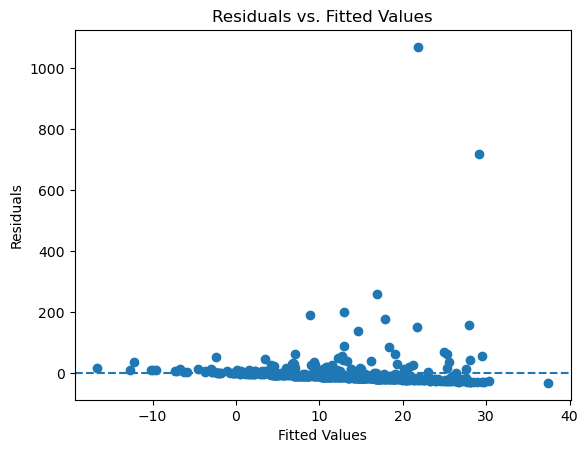

In [30]:
# Create a residuals vs. fitted values plot:
plt.scatter(baseline_model.fittedvalues, baseline_model.resid)
plt.axhline(y = 0, linestyle = "--")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs. Fitted Values")
plt.show()

Based on the baseline model's summary, the baseline linear model performs poorly on the raw burned area target. The residual plot also shows substantial variation in the residuals, including several extreme values.

In [31]:
# Add a quadratic term to the data that is the square of `temp`:
data["temp_squared"] = data["temp"]**2

# Create the nonlinear quadratic regression model using the Ordinary Least
# Squares (OLS) method:
quadratic_model = smf.ols(formula = "area ~ FFMC + DMC + DC + ISI + temp + " \
                          "temp_squared + RH + wind + rain", data = data).fit()

print(quadratic_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   area   R-squared:                       0.017
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.001
Date:                Tue, 29 Sep 2026   Prob (F-statistic):              0.438
Time:                        22:56:07   Log-Likelihood:                -2875.9
No. Observations:                 517   AIC:                             5772.
Df Residuals:                     507   BIC:                             5814.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        9.2127     62.549      0.147   

The quadratic temperature term was not statistically significant (p = 0.388) and did not meaningfully improve model fit. $R^2$ increased only slightly from 0.016 to 0.017, while adjusted $R^2$ actually went down from 0.001 to 0.000. Therefore, adding a quadratic temperature term does not substantially improve the baseline model.

In [32]:
# Create a regression model with an added interaction term between temperature
# and relative humidity:
interaction_model = smf.ols(formula = "area ~ FFMC + DMC + DC + ISI + temp + " \
                            "temp_squared + RH + temp * RH + wind + rain", data 
                            = data).fit()

print(interaction_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   area   R-squared:                       0.019
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.9639
Date:                Tue, 29 Sep 2026   Prob (F-statistic):              0.474
Time:                        22:56:07   Log-Likelihood:                -2875.6
No. Observations:                 517   AIC:                             5773.
Df Residuals:                     506   BIC:                             5820.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      -30.0478     79.598     -0.377   

The interaction term between temperature and relative humidity was not statistically significant (p = 0.425). The interaction model showed only a small improvement in $R^2$ from 0.017 to 0.019, while adjusted $R^2$ decreased even more to -0.001. Therefore, adding the temperature and relative humidity interaction did not meaningfully improve the model's ability to predict burned area.

In [33]:
# Create an indicator variable for summer months:
data["summer"] = data["month"].isin(["jun", "jul", "aug"]).astype(int)
print(data[["month", "summer"]].head())

# Create a regression model with the added summer indicator variable:
indicator_model = smf.ols(formula = "area ~ FFMC + DMC + DC + ISI + temp + " \
                            "temp_squared + RH + temp * RH + wind + rain + " \
                            "summer", data = data).fit()

print(indicator_model.summary())

  month  summer
0   mar       0
1   oct       0
2   oct       0
3   mar       0
4   mar       0
                            OLS Regression Results                            
Dep. Variable:                   area   R-squared:                       0.023
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     1.061
Date:                Tue, 29 Sep 2026   Prob (F-statistic):              0.391
Time:                        22:56:07   Log-Likelihood:                -2874.5
No. Observations:                 517   AIC:                             5773.
Df Residuals:                     505   BIC:                             5824.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------

Adding a summer indicator improved $R^2$ from 0.019 to 0.023, an increase of 0.004, but the indicator was not statistically significant (p = 0.156). Therefore, the categorical indicator did not meaningfully improve the model.

In [34]:
# Create a logarithmic transformation of DMC:
data["log_DMC"] = np.log(data["DMC"])

# Create a regression model using the log-transformed DMC:
log_model = smf.ols(formula = "area ~ FFMC + log_DMC + DC + ISI + temp + " \
                    "temp_squared + RH + temp * RH + wind + rain + summer", 
                    data = data).fit()

print(log_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   area   R-squared:                       0.022
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.018
Date:                Tue, 29 Sep 2026   Prob (F-statistic):              0.429
Time:                        22:56:07   Log-Likelihood:                -2874.8
No. Observations:                 517   AIC:                             5774.
Df Residuals:                     505   BIC:                             5825.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      -28.4787     79.400     -0.359   

The logarithmic transformation of DMC did not improve the model. $R^2$ decreased from 0.023 to 0.022, adjusted $R^2$ decreased from 0.001 to 0.000, and the log-transformed DMC predictor was not statistically significant (p = 0.170). Therefore, the logarithmic transformation did not meaningfully improve the model.

### Step 4: Evaluate Model Diagnostics

- Compare models using metrics like $R^2$, adjusted $R^2$, AIC, and BIC.
- Plot residuals and create Q-Q plots to assess normality.
- Identify influential observations using Cook's distance.

In [35]:
# Compare model fit metrics:
models = {"Baseline": baseline_model,
          "Quadratic": quadratic_model,
          "Interaction": interaction_model,
          "Indicator": indicator_model,
          "Log DMC": log_model}

for name, model in models.items():
    print(f"{name}:")
    print(f"    R²:            {model.rsquared:.4f}")
    print(f"    Adjusted R²:   {model.rsquared_adj:.4f}")
    print(f"    AIC:           {model.aic:.2f}")
    print(f"    BIC:           {model.bic:.2f}\n")

Baseline:
    R²:            0.0160
    Adjusted R²:   0.0005
    AIC:           5770.55
    BIC:           5808.78

Quadratic:
    R²:            0.0175
    Adjusted R²:   0.0000
    AIC:           5771.78
    BIC:           5814.27

Interaction:
    R²:            0.0187
    Adjusted R²:   -0.0007
    AIC:           5773.13
    BIC:           5819.86

Indicator:
    R²:            0.0226
    Adjusted R²:   0.0013
    AIC:           5773.08
    BIC:           5824.05

Log DMC:
    R²:            0.0217
    Adjusted R²:   0.0004
    AIC:           5773.56
    BIC:           5824.53



The models had very similar performance across the fit metrics. The indicator model had the highest $R^2$ (0.0226) and adjusted $R^2$ (0.0013), while the baseline model had the lowest AIC (5770.55) and BIC (5808.78). However, all models had very low $R^2$ values, indicating that none of these models explained much of the variation in burned area.

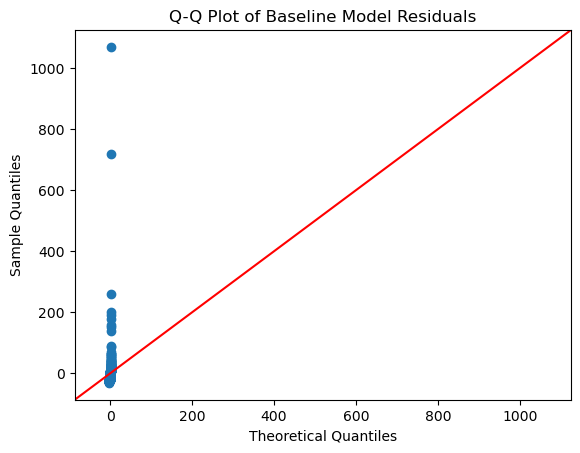

In [36]:
# Create a Q-Q plot for the baseline model residuals:
sm.qqplot(baseline_model.resid, line = "45")
plt.title("Q-Q Plot of Baseline Model Residuals")
plt.show()

The Q-Q plot shows that the residuals do not follow a normal distribution. Most of the residuals are concentrated near zero, while a small number of extreme residuals deviate substantially from the expected reference line. This indicates that the normality assumption is not well satisfied for the baseline model.

In [37]:
# Calculate Cook's distance for the baseline model:
influence = baseline_model.get_influence()
cooks_distance = influence.cooks_distance[0]

print(f"Maximum Cook's distance: {cooks_distance.max():.4f}")
print(f"Number of observations with Cook's distance > 1: {(cooks_distance > 1).
      sum()}")

Maximum Cook's distance: 0.2084
Number of observations with Cook's distance > 1: 0


The maximum Cook's distance was 0.2084, and no observations had a Cook's distance greater than 1. Therefore, there are no highly influential observations based on this threshold.

### Step 5: Apply Regularization

- Use Ridge (L2) and Lasso (L1) Regression from `sklearn` to handle multicollinearity.
- Extract the coefficients and calculate the Mean Squared Error (MSE).
- Compare the performance of the Ridge and Lasso models.

In [38]:
# Standardize the predictor variables:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_reg)

# Create and fit the Ridge regression model:
ridge_model = Ridge(alpha = 1.0)
ridge_model.fit(X_scaled, y_reg)

# Create and fit the Lasso regression model:
lasso_model = Lasso(alpha = 1.0)
lasso_model.fit(X_scaled, y_reg)

print("Ridge coefficients:")
print(ridge_model.coef_)

print("\nLasso coefficients:")
print(lasso_model.coef_)

Ridge coefficients:
[-0.12704419  4.87224839 -1.38980203 -3.16631698  4.90226218 -3.1972439
  2.72417996 -0.74829452]

Lasso coefficients:
[-0.          2.70469495  0.         -1.05303482  3.31609934 -2.46952318
  1.10526745 -0.        ]


In [39]:
# Calculate the Mean Squared Error (MSE) for each regularized model:
ridge_predictions = ridge_model.predict(X_scaled)
lasso_predictions = lasso_model.predict(X_scaled)

ridge_mse = mean_squared_error(y_reg, ridge_predictions)
lasso_mse = mean_squared_error(y_reg, lasso_predictions)

print(f"Ridge MSE: {ridge_mse:.4f}")
print(f"Lasso MSE: {lasso_mse:.4f}")

Ridge MSE: 3979.4666
Lasso MSE: 3988.2152


In [40]:
# Compare the Ridge and Lasso models:
print("Regularization Model Comparison:")
print(f"Ridge MSE: {ridge_mse:.4f}")
print(f"Lasso MSE: {lasso_mse:.4f}")
print(f"Ridge has the lower MSE by: {lasso_mse - ridge_mse:.4f}")

Regularization Model Comparison:
Ridge MSE: 3979.4666
Lasso MSE: 3988.2152
Ridge has the lower MSE by: 8.7486


The Ridge and Lasso models produced similar MSE values, with Ridge having the lower MSE (3979.4666) compared with Lasso (3988.2152). Ridge retained all eight predictors while shrinking their coefficients, whereas Lasso reduced the coefficients for `FFMC`, `DC`, and `rain` to zero. Based on MSE, Ridge performed slightly better than Lasso, although the difference between the two models was small.

### Step 6: Prepare the Data for Binary Classification

- Create a binary target variable based on a threshold in `y` (e.g. the median or another percentile).
- Select relevant predictors and scale them using `StandardScaler()`.

In [41]:
# Use the median burned area as the threshold:
threshold = data["area"].median()

# Create a binary target variable:
data["LargeArea"] = (data["area"] > threshold).astype(int)

print(f"Median burned area threshold: {threshold}")
print(data["LargeArea"].value_counts())

Median burned area threshold: 0.52
LargeArea
0    259
1    258
Name: count, dtype: int64


In [42]:
# Reuse the selected predictors we already created in Step 3 called `X_reg`:
# X_reg = data[["FFMC", "DMC", "DC", "ISI", "temp", "RH", "wind", "rain"]]
# Use the binary target variable as our response variable:
y_class = data["LargeArea"]

# Split the data into training and testing sets:
seed = 42
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_class,
                                                    test_size = 0.3,
                                                    random_state = seed)

# Scale the predictor variables:
# We already defined `scaler = StandardScaler()` in Step 5.
# Transform the `X_train` and `X_test` predictors:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled.shape, X_test_scaled.shape, y_train.shape, y_test.shape

((361, 8), (156, 8), (361,), (156,))

### Step 7: Train and Evaluate a Logistic Regression Model

- Train a logistic regression model using the scaled predictors.
- Display the coefficients and the intercept.
- Predict the probabilities and binary outcomes.
- Evaluate its performance using accuracy, the confusion matrix, precision, recall, and the F1 score.

In [43]:
# Train a logistic regression model using the scaled predictors:
model = LogisticRegression().fit(X_train_scaled, y_train)

# Display the coefficients and the intercept:
print("Logistic Regression Values:")
print(f"Coefficients: {model.coef_}")
print(f"Intercept:    {model.intercept_}")

Logistic Regression Values:
Coefficients: [[ 0.24381089 -0.04609796  0.14701214 -0.16957127  0.07076855  0.12016008
   0.22697549  0.0433229 ]]
Intercept:    [0.00263577]


In [44]:
# The predicted probabilities reflect the likelihood of each test observation
# belonging to the positive class (`LargeArea` = 1/True). Predictions are
# converted to binary classes using a default threshold of 0.5, thereby
# capturing the model's decision boundary.

# Predict the probabilities of each fire in `X_test_scaled` having `LargeArea`
# = 1/True:
# `model.predict_proba()` actually gives two probabilities for every
# observation:
# Probability of 0    Probability of 1
# The two probabilities for each observation always add up to 1. The `[:, 1]` is
# telling Python: "Give me the probability corresponding to class 1, for every
# observation." That's why `y_pred_prob` contains just the `LargeArea`
# probabilities.
y_pred_prob = model.predict_proba(X_test_scaled)[:, 1]

# Using these probabilities, and the threshold that prob ≥ 0.5 --> 1/True,
# predict the classes for each fire in `X_test_scaled`:
y_pred_class = model.predict(X_test_scaled)

# Print the first five elements of both of these arrays:
print(f"First five predicted probabilities: {y_pred_prob[0:5]}")
print(f"First five predicted classes: {y_pred_class[0:5]}")

First five predicted probabilities: [0.54771603 0.60192441 0.44670627 0.52476709 0.46950505]
First five predicted classes: [1 1 0 1 0]


In [45]:
# Evaluate the performance of the logistic regression model:

# Accuracy score: What is the proportion of all observations that were
# predicted correctly?:
logistic_accuracy = round(accuracy_score(y_test, y_pred_class), 4)

# Confusion matrix:
# A confusion matrix from `sklearn` is arranged as:
#           Predicted
#           0   1
# Actually
#        0  #   #
#        1  #   #
# This can also be represented as:
#                           Predicted
#                     0                     1
# Actually
#        0  # of True Negatives    # of False Positives
#        1  # of False Negatives   # of True Positives

logistic_confusion_matrix = confusion_matrix(y_test, y_pred_class)

# Precision: What is the proportion of all observations that were predicted to
# be positive, and actually were positive?:
logistic_precision = round(precision_score(y_test, y_pred_class), 4)

# Recall: What is the proportion of actual positive observations that were
# correctly predicted as positive?:
logistic_recall = round(recall_score(y_test, y_pred_class), 4)

# F1 score: Combines precision and recall into one metric using their harmonic
# mean:
logistic_f1 = round(f1_score(y_test, y_pred_class), 4)

print("Logistic Regression Performance:")
print(f"Accuracy Score:   {logistic_accuracy}")
print(f"Confusion Matrix: \n{logistic_confusion_matrix}")
print(f"Precision:        {logistic_precision}")
print(f"Recall:           {logistic_recall}")
print(f"F1 Score:         {logistic_f1}")

Logistic Regression Performance:
Accuracy Score:   0.5064
Confusion Matrix: 
[[39 40]
 [37 40]]
Precision:        0.5
Recall:           0.5195
F1 Score:         0.5096


The logistic regression model had an accuracy of 0.5064, meaning it correctly classified about 51% of the test observations. Precision was 0.5000, recall was 0.5195, and the F1-score was 0.5096. The confusion matrix shows similar numbers of correct and incorrect predictions for both classes. Overall, the model did not perform substantially better than chance at distinguishing between smaller and larger burned areas.

### Step 8: Check Assumptions

Use the Variance Inflation Factor (VIF) to assess multicollinearity among the predictors.

In [46]:
# VIF (Variance Inflation Factor) measures multicollinearity, which is
# essentially how much one predictor can be explained by the other predictors
# in the model. A VIF of 1 means there is essentially no multicollinearity
# involving that predictor.

# Calculate the VIF for each predictor:
vif = pd.DataFrame()
vif["Variable"] = X_train.columns
vif["VIF"] = [variance_inflation_factor(X_train_scaled, i)
              for i in range(X_train_scaled.shape[1])]

# Round the VIFs to three decimal places:
round(vif, 3)

,Variable,VIF
0,FFMC,1.766
1,DMC,2.375
2,DC,2.146
3,ISI,1.808
4,temp,2.696
5,RH,2.049
6,wind,1.154
7,rain,1.046


The VIF values ranged from 1.046 to 2.696, with `rain` having the lowest value and `temp` having the highest value. All of the predictors had relatively low VIF values, indicating that there is not a strong multicollinearity problem among the predictors used in the logistic regression model.

### Step 9: Summarize Findings

- Compare regression models and classification results.
- Highlight trade-offs between model simplicity, performance, and interpretability.
- Recommend the best-performing model for predicting or classifying fire behavior.

The regression models performed poorly overall. The baseline model had the lowest AIC and BIC, while the indicator model had the highest $R^2$ and adjusted $R^2$. However, all of the models had extremely low $R^2$ values, indicating that they explained very little of the variation in burned area. The baseline model also used fewer additional terms than the more complex models, making it easier to interpret. The Ridge model had a slightly lower MSE than the Lasso model, although their MSE values were very similar. Lasso reduced three predictor coefficients to zero, which can make the model more interpretable by effectively removing those predictors.

The logistic regression model also performed poorly. Its accuracy was close to 50%, with precision, recall, and F1 scores also close to 0.50. Since the classes were approximately balanced, this indicates that the model performed about as well as chance when classifying observations into smaller and larger burned areas. The VIF values were all relatively low, so there was not a strong multicollinearity problem among the predictors. However, the residual analysis showed that the normality assumption was not well satisfied for the regression models.

Overall, the baseline regression model is the preferred model among the regression models tested because it had the lowest AIC and BIC while maintaining a simpler structure. However, its very low $R^2$ indicates that it is still not a strong model for predicting burned area. The logistic regression model also did not provide useful classification performance. Therefore, the results suggest that the variables included in these models do not provide enough information to reliably predict or classify fire behavior in this dataset.

The results also suggest that the main limitation may be the information contained in the available predictors rather than simply the choice of regression model. Several reasonable changes to the regression model, including nonlinear terms, an interaction term, a seasonal indicator, and a logarithmic transformation, produced only small changes in performance. The classification model also performed close to chance. Therefore, continuing to add complexity to these models would not necessarily solve the problem. A better approach for improving predictions would likely involve identifying additional variables that contain more information about the factors that determine burned area, while also evaluating more flexible models using appropriate validation methods.